In [2]:

import argparse
import csv
import random
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests
import tifffile
import torch
from scipy.ndimage import gaussian_filter, map_coordinates
from torch import nn
from torch.utils.data import DataLoader, Dataset

DATA_URL = "https://downloads.imagej.net/ISBI-2012-challenge.zip"

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Full CUDA determinism can affect performance; fixed seeds improve reproducibility.

In [3]:
# %% [B] Download and load the original ISBI 2012 data

def download_isbi_data(data_dir="data/isbi2012", url=DATA_URL):
    """Download the original challenge ZIP and extract the TIFF stacks.

    You may instead manually download the ZIP from DATA_URL and place the TIFF
    files (at any depth) inside data_dir. A test ground truth is NOT needed.
    """
    folder = Path(data_dir)
    folder.mkdir(parents=True, exist_ok=True)
    try:
        find_tiff(folder, "train-volume.tif")
        find_tiff(folder, "train-labels.tif")
        print("ISBI dataset already exists:", folder)
        return folder
    except FileNotFoundError:
        pass

    archive = folder / "ISBI-2012-challenge.zip"
    if not archive.exists():
        print("Downloading the ISBI 2012 dataset:", url)
        try:
            with requests.get(url, stream=True, timeout=90) as response:
                response.raise_for_status()
                with archive.open("wb") as out:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        if chunk:
                            out.write(chunk)
        except Exception as exc:
            archive.unlink(missing_ok=True)
            raise RuntimeError(
                "Automatic download failed. Download the ZIP manually from "
                f"{url}, extract into '{folder}', then rerun. Cause: {exc}"
            ) from exc
    with zipfile.ZipFile(archive, "r") as zf:
        for member in zf.infolist():
            # Defensive check for safe paths inside ZIP.
            target = (folder / member.filename).resolve()
            if not target.is_relative_to(folder.resolve()):
                raise RuntimeError("Unsafe ZIP member path: " + member.filename)
        zf.extractall(folder)
    find_tiff(folder, "train-volume.tif")
    find_tiff(folder, "train-labels.tif")
    print("Extracted ISBI dataset into:", folder)
    return folder


def find_tiff(data_dir, name):
    matches = list(Path(data_dir).rglob(name))
    if not matches:
        raise FileNotFoundError(f"Missing {name} under {data_dir}. See {DATA_URL}")
    return matches[0]


def load_isbi_data(data_dir="data/isbi2012"):
    """Return (images, masks) as float32 arrays shaped [N, 512, 512].

    Mask = 1 for annotated cell interiors (white), 0 for membranes (black).
    """
    images = tifffile.imread(find_tiff(data_dir, "train-volume.tif"))
    labels = tifffile.imread(find_tiff(data_dir, "train-labels.tif"))
    if images.ndim != 3 or labels.ndim != 3:
        raise ValueError(f"Expected multi-page TIFFs: got {images.shape}, {labels.shape}")
    if images.shape[0] == 512 and images.shape[-1] == 30:
        images = np.moveaxis(images, -1, 0)
    if labels.shape[0] == 512 and labels.shape[-1] == 30:
        labels = np.moveaxis(labels, -1, 0)
    if images.shape != labels.shape:
        raise ValueError(f"Image and mask dimensions differ: {images.shape}, {labels.shape}")
    images = images.astype(np.float32) / 255.0
    labels = (labels > 127).astype(np.float32)
    print(f"Images: {images.shape}; masks: {labels.shape}; mask white share: {labels.mean():.2%}")
    return images, labels

Extracted ISBI dataset into: data/isbi2012
Images: (30, 512, 512); masks: (30, 512, 512); mask white share: 78.04%


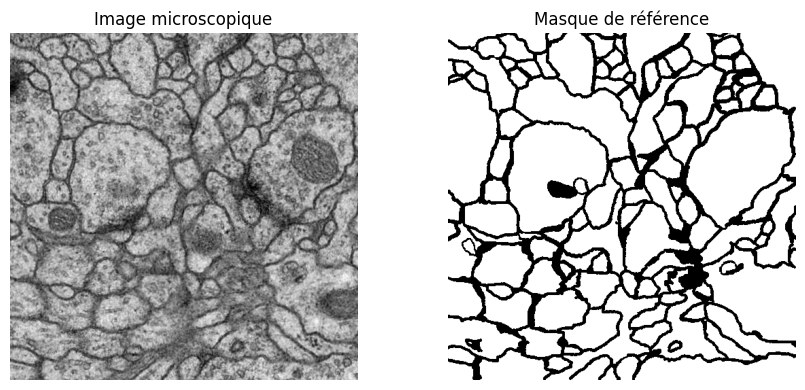

In [4]:
import zipfile
from pathlib import Path
import requests

# Redéfinition robuste de la fonction de téléchargement pour éviter l'erreur de chemin "/"
def download_isbi_data_fixed(data_dir="data/isbi2012", url=DATA_URL):
    folder = Path(data_dir)
    folder.mkdir(parents=True, exist_ok=True)
    try:
        find_tiff(folder, "train-volume.tif")
        find_tiff(folder, "train-labels.tif")
        print("ISBI dataset already exists:", folder)
        return folder
    except FileNotFoundError:
        pass

    archive = folder / "ISBI-2012-challenge.zip"
    if not archive.exists():
        print("Downloading the ISBI 2012 dataset:", url)
        try:
            with requests.get(url, stream=True, timeout=90) as response:
                response.raise_for_status()
                with archive.open("wb") as out:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        if chunk:
                            out.write(chunk)
        except Exception as exc:
            archive.unlink(missing_ok=True)
            raise RuntimeError(f"Automatic download failed: {exc}") from exc

    with zipfile.ZipFile(archive, "r") as zf:
        for member in zf.infolist():
            # On ignore les dossiers racines ou vides comme "/"
            if member.filename.strip() in ("/", "") or member.filename.startswith("/"):
                continue
            target = (folder / member.filename).resolve()
            if not target.is_relative_to(folder.resolve()):
                raise RuntimeError("Unsafe ZIP member path: " + member.filename)
        zf.extractall(folder)
    find_tiff(folder, "train-volume.tif")
    find_tiff(folder, "train-labels.tif")
    print("Extracted ISBI dataset into:", folder)
    return folder

DATA_DIR = "data/isbi2012"
download_isbi_data_fixed(DATA_DIR)
images, masks = load_isbi_data(DATA_DIR)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(images[0], cmap="gray")
axes[0].set_title("Image microscopique")
axes[1].imshow(masks[0], cmap="gray")
axes[1].set_title("Masque de référence")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

In [5]:
# %% [C] Paired augmentation and PyTorch datasets

def elastic_transform_pair(image, mask, alpha=14.0, sigma=8.0):
    """Apply identical elastic displacement to image and mask.

    Cubic/linear interpolation for the image; nearest-neighbour for the labels.
    """
    h, w = image.shape
    dy = gaussian_filter((np.random.rand(h, w) * 2 - 1), sigma) * alpha
    dx = gaussian_filter((np.random.rand(h, w) * 2 - 1), sigma) * alpha
    yy, xx = np.meshgrid(np.arange(h), np.arange(w), indexing="ij")
    coords = (yy + dy, xx + dx)
    img = map_coordinates(image, coords, order=1, mode="reflect")
    msk = map_coordinates(mask, coords, order=0, mode="nearest")
    return img, msk


class ISBIDataset(Dataset):
    def __init__(self, images, masks, indices, train=True,
                 patch_size=256, patches_per_image=12, elastic_prob=0.25):
        self.images = images
        self.masks = masks
        self.indices = list(indices)
        self.train = train
        self.patch_size = patch_size
        self.patches_per_image = patches_per_image
        self.elastic_prob = elastic_prob
        if train and patch_size > min(images.shape[-2:]):
            raise ValueError("patch_size cannot exceed the TIFF image dimensions")

    def __len__(self):
        return len(self.indices) * (self.patches_per_image if self.train else 1)

    def __getitem__(self, i):
        idx = self.indices[i % len(self.indices)] if self.train else self.indices[i]
        image = self.images[idx].copy()
        mask = self.masks[idx].copy()
        if self.train:
            ph = pw = self.patch_size
            h, w = image.shape
            y = random.randint(0, h - ph)
            x = random.randint(0, w - pw)
            image = image[y:y + ph, x:x + pw]
            mask = mask[y:y + ph, x:x + pw]
            if random.random() < 0.5:
                image, mask = np.fliplr(image), np.fliplr(mask)
            if random.random() < 0.5:
                image, mask = np.flipud(image), np.flipud(mask)
            turns = random.randrange(4)
            image, mask = np.rot90(image, turns), np.rot90(mask, turns)
            if random.random() < self.elastic_prob:
                image, mask = elastic_transform_pair(image, mask)
            # Contrast/brightness augmentation applies only to the image.
            contrast = random.uniform(0.85, 1.15)
            brightness = random.uniform(-0.08, 0.08)
            image = np.clip((image - 0.5) * contrast + 0.5 + brightness, 0.0, 1.0)
        image = torch.from_numpy(np.ascontiguousarray(image)).unsqueeze(0).float()
        mask = torch.from_numpy(np.ascontiguousarray(mask)).unsqueeze(0).float()
        return image, mask

In [6]:
# %% [D] U-Net encoder-decoder with symmetric skip connections

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, padding=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=padding),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=padding),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UpBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels, padding=1):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.conv = DoubleConv(out_channels + skip_channels, out_channels, padding=padding)

    def forward(self, x, skip):
        x = self.up(x)
        # In 'valid' mode original U-Net crops encoder features before concatenation.
        dh = skip.size(2) - x.size(2)
        dw = skip.size(3) - x.size(3)
        if dh >= 0 and dw >= 0:
            skip = skip[:, :, dh // 2:dh // 2 + x.size(2), dw // 2:dw // 2 + x.size(3)]
        else:
            # Robust with odd sizes if same-padding option is used.
            x = nn.functional.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.conv(torch.cat([skip, x], dim=1))


class UNet(nn.Module):
    """5-resolution-level U-Net (4 down and 4 up blocks).

    padding='same': practical option: 256x256 -> 256x256, easy to train.
    padding='valid': matches paper's unpadded architecture:
                     e.g. 572x572 -> 388x388 (requires larger input).
    """
    def __init__(self, in_channels=1, out_channels=1, base_channels=16, padding="same"):
        super().__init__()
        if padding not in ("same", "valid"):
            raise ValueError("padding must be 'same' or 'valid'")
        p = 1 if padding == "same" else 0
        b = base_channels
        self.enc1 = DoubleConv(in_channels, b, p)
        self.enc2 = DoubleConv(b, b * 2, p)
        self.enc3 = DoubleConv(b * 2, b * 4, p)
        self.enc4 = DoubleConv(b * 4, b * 8, p)
        self.bottleneck = DoubleConv(b * 8, b * 16, p)
        self.pool = nn.MaxPool2d(2)
        self.up4 = UpBlock(b * 16, b * 8, b * 8, p)
        self.up3 = UpBlock(b * 8, b * 4, b * 4, p)
        self.up2 = UpBlock(b * 4, b * 2, b * 2, p)
        self.up1 = UpBlock(b * 2, b, b, p)
        self.out_conv = nn.Conv2d(b, out_channels, kernel_size=1)

    def forward(self, x):
        x1 = self.enc1(x)
        x2 = self.enc2(self.pool(x1))
        x3 = self.enc3(self.pool(x2))
        x4 = self.enc4(self.pool(x3))
        x5 = self.bottleneck(self.pool(x4))
        x = self.up4(x5, x4)
        x = self.up3(x, x3)
        x = self.up2(x, x2)
        x = self.up1(x, x1)
        return self.out_conv(x)  # logits, no Sigmoid (loss expects logits)

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
model = UNet(in_channels=1, out_channels=1, base_channels=16, padding="same")
x = torch.zeros(1, 1, 256, 256)
with torch.no_grad(): y = model(x)
print("U-Net same padding:", tuple(x.shape), "->", tuple(y.shape))
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
del x, y

Device: cuda
U-Net same padding: (1, 1, 256, 256) -> (1, 1, 256, 256)
Trainable parameters: 1940817


In [8]:
# %% [E] Training loss and segmentation metrics

def loss_bce_dice(logits, target, dice_weight=0.5):
    bce = nn.functional.binary_cross_entropy_with_logits(logits, target)
    probs = logits.sigmoid()
    reduce_dims = (1, 2, 3)
    intersection = (probs * target).sum(dim=reduce_dims)
    denominator = probs.sum(dim=reduce_dims) + target.sum(dim=reduce_dims)
    soft_dice = (2 * intersection + 1.0) / (denominator + 1.0)
    return (1 - dice_weight) * bce + dice_weight * (1 - soft_dice.mean())


def segmentation_metrics(logits, target, threshold=0.5):
    predicted = (logits.sigmoid() >= threshold).float()
    target = target.float()
    tp = (predicted * target).sum().item()
    fp = (predicted * (1 - target)).sum().item()
    fn = ((1 - predicted) * target).sum().item()
    dice = (2 * tp + 1e-7) / (2 * tp + fp + fn + 1e-7)
    iou = (tp + 1e-7) / (tp + fp + fn + 1e-7)
    return dice, iou


def run_epoch(model, loader, optimizer, device, train):
    model.train(mode=train)
    total_loss = 0.0
    total_dice = 0.0
    total_iou = 0.0
    total_count = 0
    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)
        with torch.set_grad_enabled(train):
            logits = model(images)
            if logits.shape != masks.shape:
                raise RuntimeError("Training uses padding='same'. Mask/output sizes must match.")
            loss = loss_bce_dice(logits, masks)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
        batch_n = images.shape[0]
        dice, iou = segmentation_metrics(logits.detach(), masks)
        total_loss += loss.item() * batch_n
        total_dice += dice * batch_n
        total_iou += iou * batch_n
        total_count += batch_n
    return {"loss": total_loss / total_count,
            "dice": total_dice / total_count,
            "iou": total_iou / total_count}

In [9]:
# %% [F] Plots and reproducible training routine

def plot_history(history, output_dir):
    import matplotlib.pyplot as plt
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    epochs = [r["epoch"] for r in history]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, key in zip(axes, ("loss", "dice", "iou")):
        ax.plot(epochs, [r[f"train_{key}"] for r in history], label="Train")
        ax.plot(epochs, [r[f"val_{key}"] for r in history], label="Validation")
        ax.set(xlabel="Epoch", ylabel=key.upper(), title=f"{key.upper()} by epoch")
        ax.legend()
        ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(output_dir / "learning_curves.png", dpi=160)
    plt.show()
    plt.close(fig)


def show_prediction(model, dataset, device, output_dir=None, idx=0):
    model.eval()
    image, mask = dataset[idx]
    with torch.no_grad():
        prob = model(image.unsqueeze(0).to(device)).sigmoid()[0, 0].cpu().numpy()
    pred = prob >= 0.5
    fig, ax = plt.subplots(1, 4, figsize=(14, 4))
    for a, val, title in zip(ax,
                             (image[0].numpy(), mask[0].numpy(), prob, pred),
                             ("Microscopy", "Ground truth", "Probabilities", "Prediction")):
        a.imshow(val, cmap="gray", vmin=0, vmax=1)
        a.set_title(title)
        a.axis("off")
    fig.tight_layout()
    if output_dir is not None:
        fig.savefig(Path(output_dir) / "validation_prediction.png", dpi=160)
    plt.show()
    plt.close(fig)


def train_experiment(data_dir="data/isbi2012", output_dir="outputs", epochs=25,
                     batch_size=4, patch_size=256, patches_per_image=12,
                     base_channels=16, lr=1e-3, seed=42, elastic_prob=0.25,
                     num_workers=0, download=True):
    """Train on 24 slices, validate on the final 6 slices (not test set)."""
    seed_everything(seed)
    if download:
        download_isbi_data(data_dir)
    images, masks = load_isbi_data(data_dir)
    # Keep consecutive slices in validation: reduce adjacent-slice leakage.
    split = int(round(len(images) * 0.8))
    train_indices, val_indices = np.arange(split), np.arange(split, len(images))
    print("Train slices:", list(train_indices), "\nValidation slices:", list(val_indices))
    train_ds = ISBIDataset(images, masks, train_indices, train=True,
                           patch_size=patch_size, patches_per_image=patches_per_image,
                           elastic_prob=elastic_prob)
    val_ds = ISBIDataset(images, masks, val_indices, train=False)
    train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                          num_workers=num_workers, pin_memory=torch.cuda.is_available())
    val_dl = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=num_workers)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device:", device)
    model = UNet(base_channels=base_channels, padding="same").to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)
    history = []
    best_iou = -1.0
    for epoch in range(1, epochs + 1):
        tr = run_epoch(model, train_dl, optimizer, device, train=True)
        va = run_epoch(model, val_dl, optimizer=None, device=device, train=False)
        row = {"epoch": epoch, **{f"train_{k}": v for k, v in tr.items()},
               **{f"val_{k}": v for k, v in va.items()}}
        history.append(row)
        print(f"Epoch {epoch:03}/{epochs} | "
              f"train loss={tr['loss']:.4f}, IoU={tr['iou']:.4f} | "
              f"val loss={va['loss']:.4f}, Dice={va['dice']:.4f}, IoU={va['iou']:.4f}")
        if va["iou"] > best_iou:
            best_iou = va["iou"]
            torch.save({"model_state": model.state_dict(), "epoch": epoch,
                        "val_iou": best_iou, "base_channels": base_channels,
                        "padding": "same", "seed": seed}, out / "best_unet.pt")
    with (out / "training_history.csv").open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(history[0].keys()))
        writer.writeheader()
        writer.writerows(history)
    saved = torch.load(out / "best_unet.pt", map_location=device, weights_only=True)
    model.load_state_dict(saved["model_state"])
    print(f"Best validation IoU: {best_iou:.4f} (epoch {saved['epoch']}).")
    plot_history(history, out)
    show_prediction(model, val_ds, device, out, idx=0)
    return model, history, (train_ds, val_ds)

Images: (30, 512, 512); masks: (30, 512, 512); mask white share: 78.04%
Train slices: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)] 
Validation slices: [np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29)]
Device: cuda
Epoch 001/40 | train loss=0.4084, IoU=0.7648 | val loss=0.2667, Dice=0.8910, IoU=0.8035
Epoch 002/40 | train loss=0.2796, IoU=0.7767 | val loss=0.2499, Dice=0.8865, IoU=0.7963
Epoch 003/40 | train loss=0.2560, IoU=0.8031 | val loss=0.2361, Dice=0.9000, IoU=0.8183
Epoch 004/40 | train loss=0.2490, IoU=0.8146 | val loss=0.1968, Dice=0.9272, IoU=0.8643
Epoch 005/40 | train loss=0.2411, IoU=0.8204 | val loss=0.1945, Dice=0.9264, IoU=0.8631
Epoch 006/40 | train loss=0.2

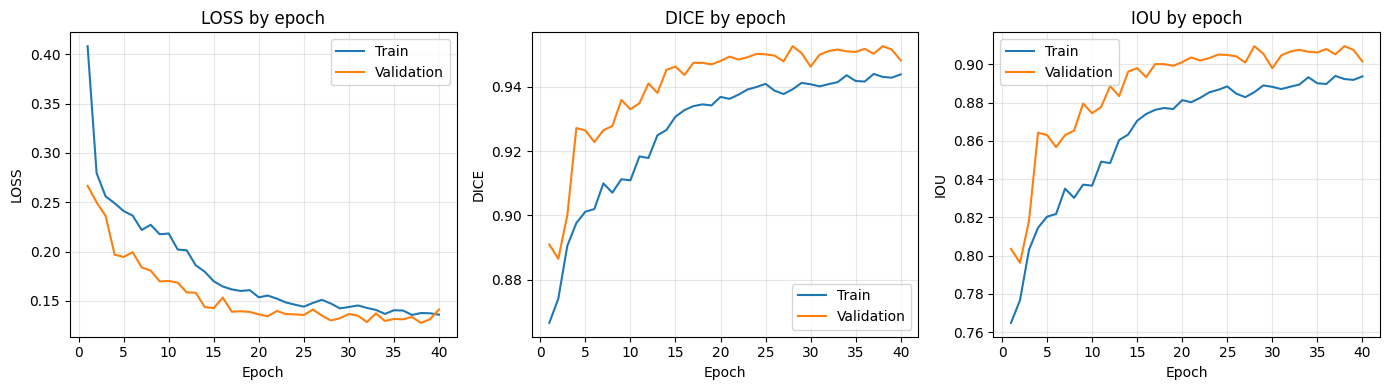

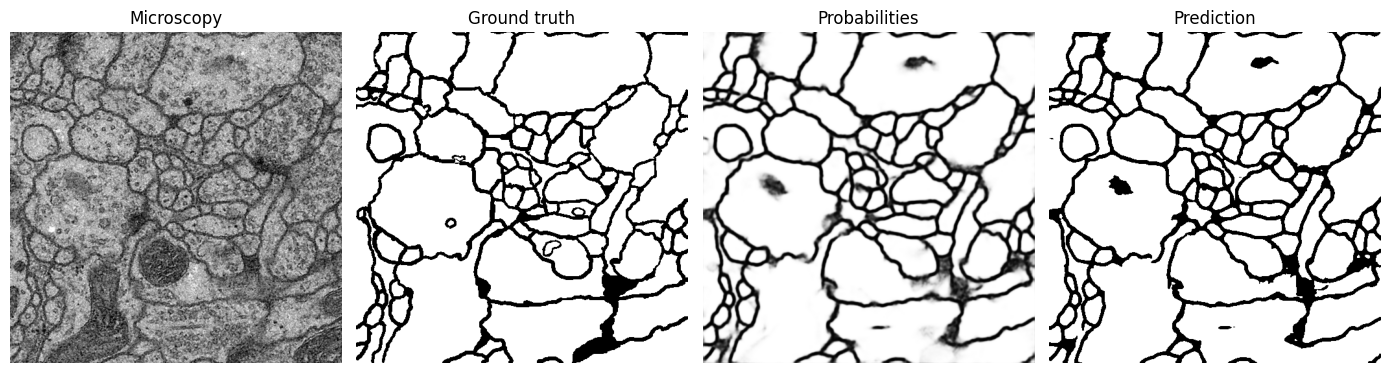

In [12]:
EPOCHS = 40
BATCH_SIZE = 4
PATCH_SIZE = 256
BASE_CHANNELS = 16
LEARNING_RATE = 1e-3
ELASTIC_PROB = 0.25

model, history, (train_ds, val_ds) = train_experiment(
    data_dir=DATA_DIR,
    output_dir="outputs",
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    patch_size=PATCH_SIZE,
    base_channels=BASE_CHANNELS,
    lr=LEARNING_RATE,
    elastic_prob=ELASTIC_PROB,
    download=False,
)

In [11]:
# Facultatif : dans Google Colab, télécharger les résultats localement.
# from google.colab import files
# files.download("outputs/learning_curves.png")
# files.download("outputs/training_history.csv")
# files.download("outputs/best_unet.pt")